# Pipeline Fase 2 — Mesin OCR sebagai Variabel pada Klasifikasi Dokumen Multimodal

Satu notebook yang menjalankan seluruh penelitian dari nol sampai hasil akhir:
setup → data → split → EDA → OCR multi-mesin → fitur teks → training unimodal →
dua aturan fusi → uji hipotesis → ringkasan.

**Rancangan** (lihat `review-1/pipeline-usulan/main.pdf` dan
`vault/00-index/rencana-prompt.md`):

| Komponen | Isi |
|---|---|
| Data | Tobacco3482 saja; 800 latih terstratifikasi (80 di antaranya validasi), 2.682 uji; seed 42/43/44; tanpa RVL-CDIP |
| Variabel bebas 1 | Mesin OCR: QS-OCR (acuan, Tesseract 4 dari TIF), Tesseract (JPG), EasyOCR, PaddleOCR |
| Variabel bebas 2 | Aturan fusi: **CONCAT** (fitur, gaya Audebert) vs **LATE** (rata-rata logit, gaya Kashyap) |
| Dikontrol | MobileNetV2, FastText subword + CNN 1D, hiperparameter, teks mentah tanpa praproses |
| Terikat | OA, macro-F1, F1 per kelas, akurasi tiap unimodal, penurunan akurasi saat satu modalitas dikosongkan |
| Uji | rerata ± simpangan baku 3 seed, McNemar berpasangan dengan koreksi Holm per seed |

Hipotesis kerja: **H1** mesin OCR mengubah akurasi cabang teks secara nyata;
**H3** cabang teks yang lebih kuat membuat fusi lebih memakai teks, dan rata-rata logit
lebih tahan terhadap cabang yang timpang daripada konkatenasi. (H2, BERT, adalah
*future work*.)

**Cara pakai:** atur sel `RUN` di bawah, lalu *Run All*. Semua logika ada di `src/`;
notebook ini hanya memanggilnya. Bagian mahal (OCR, fitur, training) **bisa dilanjutkan**:
hasil yang sudah ada di disk dipakai ulang, jadi kalau kernel mati cukup *Run All* lagi.

Aturan proyek: angka di catatan vault hanya disalin dari keluaran notebook ini.

In [34]:
# ===== Satu-satunya sel yang perlu diatur =====
import os

RUN = {
    # Bawaan dibaca dari run_all.py (--cepat / --timpa); boleh diganti True/False langsung.
    "quick": os.environ.get("APDM_CEPAT") == "1",      # True: 1 seed, epoch dipangkas
    "overwrite": os.environ.get("APDM_TIMPA") == "1",  # True: latih ulang walau hasil ada
    "run_ocr": True,         # False: pakai teks OCR yang sudah ada di data/interim/ocr
    "ocr_engines": ["tesseract", "easyocr", "paddleocr"],   # mesin yang dijalankan
    "ocr_trial_pages": 20,   # uji kecepatan per mesin sebelum run penuh
    "paddle_models": "mobile",   # "mobile" (PP-OCRv5) | "default" (lebih lambat)
    "run_training": True,    # False: berhenti setelah fitur teks (untuk cek estimasi waktu)
    # EDA
    "flag_percentile": 5,    # ekor distribusi yang ditandai (persen), dari data
    "dup_min_corr": 0.98,    # korelasi thumbnail minimum kandidat duplikat
    "dup_min_jaccard": 0.8,  # kemiripan teks minimum untuk mengonfirmasi duplikat
    "stats_width": 1000,     # lebar seragam (px) saat menghitung statistik citra
    "tsne_perplexity": 30,
}

os.environ["APDM_CEPAT"] = "1" if RUN["quick"] else "0"
os.environ["APDM_TIMPA"] = "1" if RUN["overwrite"] else "0"

## 1. Setup lingkungan

In [35]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
print("root proyek:", ROOT, "| python", sys.version.split()[0])
if sys.version_info[:2] != (3, 12):
    print("CATATAN: proyek diuji pada Python 3.12; versi lain mungkin belum punya wheel.")

%pip install -q -r "{ROOT / 'requirements.txt'}"

root proyek: e:\TESIS\apdam-project\apdm-document-classification | python 3.12.10
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
# GPU: kalau ada NVIDIA tapi torch versi CPU, pasang ulang dari indeks CUDA.
from src import setup_env as SE

info = SE.torch_info()
print("torch:", info)
if info and not info["cuda"] and SE.has_nvidia():
    print("GPU NVIDIA ada tapi torch tidak melihat CUDA -> pasang ulang dari indeks cu124")
    %pip install -q --force-reinstall torch torchvision --index-url https://download.pytorch.org/whl/cu124
    info = SE.torch_info()
    print("setelah dipasang ulang:", info, "-> RESTART kernel lalu Run All lagi.")
elif not (info and info["cuda"]):
    print("Tidak ada GPU NVIDIA: training akan sangat lambat. Pertimbangkan RUN['quick']=True.")

torch: {'versi': '2.5.1+cu121', 'cuda': True, 'nama': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'vram_gb': 4.3}


In [37]:
# Kredensial Kaggle (citra Tobacco3482). Token tidak pernah dicetak.
import getpass

if SE.kaggle_ready():
    print("kredensial Kaggle sudah ada")
elif (src := SE.adopt_kaggle_json()) is not None:
    print(f"kaggle.json dari {src} dipasang ke {SE.KAGGLE_JSON}")
else:
    print("kaggle.json tidak ditemukan. Isi dari kaggle.com -> Settings -> API.")
    user = input("Kaggle username: ").strip()
    key = getpass.getpass("Kaggle key (tidak terlihat): ").strip()
    if user and key:
        SE.write_kaggle_token(user, key)
    del key
ok, msg = SE.verify_kaggle()
print("kaggle:", "OK" if ok else "GAGAL", "-", msg)
assert ok, "Kredensial Kaggle belum bisa dipakai."

kredensial Kaggle sudah ada
kaggle: OK - Kaggle credentials successfully validated.
ramadhanialqadri


In [38]:
# Self-check semua modul src/ (tanpa dataset). Gagal di sini = jangan lanjut.
res = SE.run_self_checks()
for m, err in res.items():
    print(("OK    " if err is None else "GAGAL ") + f"src/{m}" + ("" if err is None else f"  -> {err}"))
assert all(e is None for e in res.values()), "Ada self-check yang gagal."

OK    src/config
OK    src/data
OK    src/splits
OK    src/text_features
OK    src/datasets
OK    src/models.text_models
OK    src/models.image_model
OK    src/models.fusion
OK    src/train
OK    src/ocr
OK    src/eda
OK    src/experiment
OK    src/plots
OK    src/setup_env


In [39]:
import json, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import data as D, datasets as DS, eda as EDA, experiment as EX, ocr as OCR
from src import plots as P, splits as S, text_features as TF, train as T
from src.config import CONFIG, deviasi_runtime, set_seed
from src.models import CNN1D, ImageBranch, build_transform
from src.utils import save_fig

set_seed(42)
CLASSES = CONFIG["classes"]
SEEDS = CONFIG["seeds"]
CONDITIONS = CONFIG["ocr_conditions"]
REPORTS = CONFIG["fase2_reports"]
for d in (CONFIG["fase2_data"], CONFIG["fase2_models"], REPORTS, CONFIG["data_interim"]):
    d.mkdir(parents=True, exist_ok=True)
device = T.pick_device()

def show(fig, name):
    save_fig(fig, f"fase2_{name}")
    plt.show()

print(f"device {device} | seed {SEEDS} | epoch {CONFIG['epochs']} | kondisi OCR {CONDITIONS}")
print("deviasi runtime (salin ke catatan eksperimen):")
for d in deviasi_runtime() or ["tidak ada"]:
    print("  -", d)

device cuda | seed [42, 43, 44] | epoch {'text': 100, 'image': 200, 'fusion': 200, 'head': 200} | kondisi OCR ['qs-ocr', 'tesseract', 'easyocr', 'paddleocr']
deviasi runtime (salin ke catatan eksperimen):
  - batch 40 dipecah jadi micro-batch 8 dengan akumulasi gradien; update optimizer tetap dari 40 sampel, tapi BatchNorm menormalisasi per micro-batch
  - mixed precision (AMP) aktif, tidak dipakai paper


## 2. Data: unduh, audit, pasangkan

Citra JPG dari Kaggle (`patrickaudriaz/tobacco3482jpg`, ± 3,3 GB, sekali saja) dan teks
QS-OCR-Small (2,5 MB). `prepare_dataset` mencari folder kelas, merekonsiliasi nama kelas
(`ADVE` ↔ `Advertisement`), memasangkan citra–teks per stem, lalu menulis
`data/processed/manifest.csv`. Yatim dan duplikat dilaporkan, tidak disembunyikan.

In [40]:
audit = D.prepare_dataset()
pairing = pd.DataFrame(audit["pairing"]).T[["n_pasangan", "n_citra_yatim", "n_teks_yatim"]]
pairing.loc["TOTAL"] = pairing.sum()
display(pairing)
for name in ("kandidat_citra", "kandidat_teks"):
    if "warning" in audit[name]:
        print("PERINGATAN", name, ":", audit[name]["warning"])
print("stem ganda lintas kelas -> citra:", len(audit["stem_ganda_citra"]),
      "| teks:", len(audit["stem_ganda_teks"]))

manifest = pd.read_csv(audit["manifest"], dtype={"id": str})
labels = manifest["kelas"].tolist()
y_name = manifest["kelas"].to_numpy()
y = DS.label_indices(labels)
N = len(manifest)
assert N == CONFIG["n_samples_expected"], f"{N} pasangan, harapan {CONFIG['n_samples_expected']}"
print(f"{N} pasangan citra-teks, {manifest['kelas'].nunique()} kelas")

,n_pasangan,n_citra_yatim,n_teks_yatim
Advertisement,230,0,0
Email,599,0,0
Form,431,0,0
Letter,567,0,0
Memo,620,0,0
News,188,0,0
Note,201,0,0
Report,265,0,0
Resume,120,0,0
Scientific,261,0,0


PERINGATAN kandidat_citra : 2 folder masing-masing punya 10 kelas — kemungkinan arsip bersarang duplikat. Dipilih yang path-nya terpendek.
stem ganda lintas kelas -> citra: 0 | teks: 0
3482 pasangan citra-teks, 10 kelas


## 3. Split

800 dokumen latih (80 di antaranya validasi untuk *early stopping*), sisanya 2.682 uji,
terstratifikasi, tiga seed. Deviasi dari Audebert (k-fold) dicatat di `src/splits.py`.
Indeks split dibekukan ke disk beserta sidik jari manifest.

In [41]:
S.write_splits(labels)
splits = {s: S.load_split(s, labels) for s in SEEDS}
sp = splits[SEEDS[0]]
print(f"train {len(sp['train'])} | val {len(sp['val'])} | test {len(sp['test'])}")
split_table = EDA.split_table(y_name, splits, CLASSES)
display(split_table)
split_table.to_csv(REPORTS / "eda_pembagian_data.csv", index=False)

train 720 | val 80 | test 2682


,seed,bagian,Advertisement,Email,Form,Letter,Memo,News,Note,Report,Resume,Scientific,total
0,42,train,48,124,89,117,128,39,41,55,25,54,720
1,42,val,5,14,10,13,14,4,5,6,3,6,80
2,42,test,177,461,332,437,478,145,155,204,92,201,2682
3,43,train,48,124,89,117,128,39,41,55,25,54,720
4,43,val,5,14,10,13,14,4,5,6,3,6,80
5,43,test,177,461,332,437,478,145,155,204,92,201,2682
6,44,train,48,124,89,117,128,39,41,55,25,54,720
7,44,val,5,14,10,13,14,4,5,6,3,6,80
8,44,test,177,461,332,437,478,145,155,204,92,201,2682


## 4. EDA

### 4.1 Distribusi kelas dan contoh pasangan

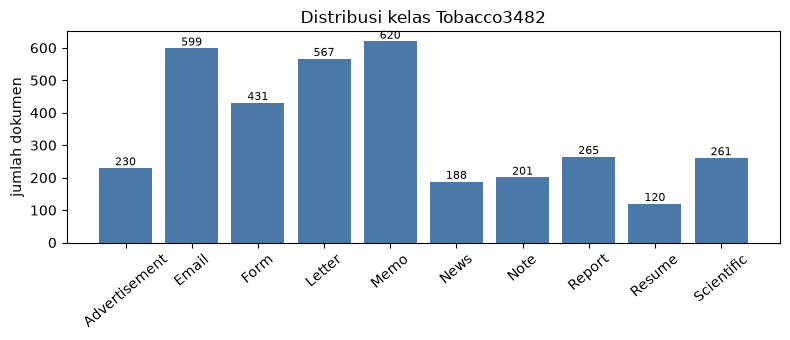

rasio kelas terbesar : terkecil = 5.17


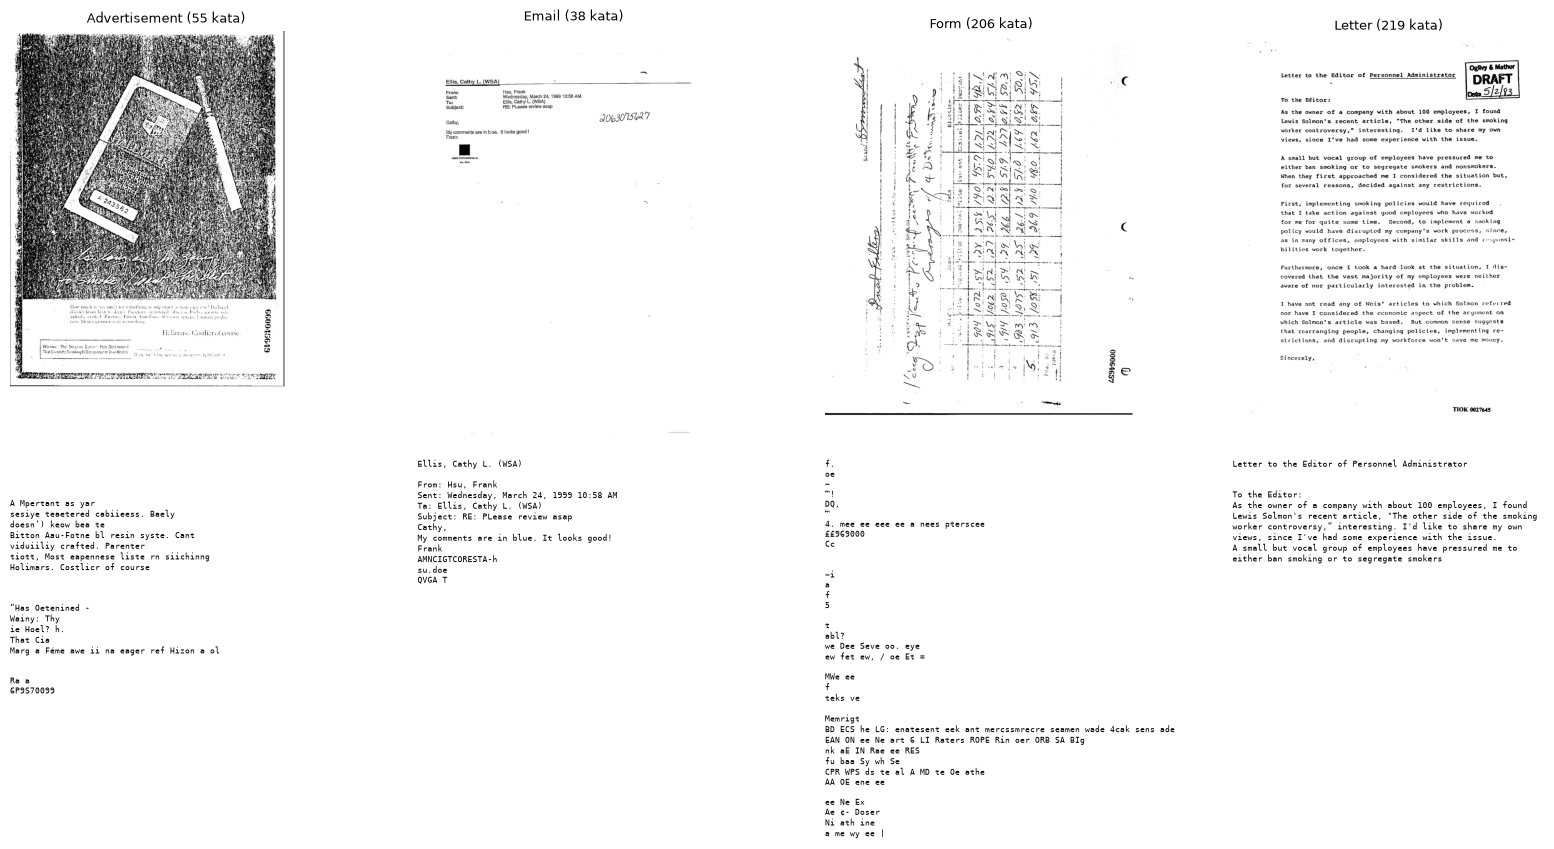

In [42]:
counts = manifest["kelas"].value_counts().reindex(CLASSES)
show(P.bar_counts(counts, "Distribusi kelas Tobacco3482"), "eda_distribusi_kelas")
print(f"rasio kelas terbesar : terkecil = {counts.max() / counts.min():.2f}")

pick = manifest.groupby("kelas").head(1).head(4)
items = [(r.path_citra, Path(r.path_teks).read_text(encoding="utf-8", errors="replace"),
          f"{r.kelas} ({r.n_kata} kata)") for r in pick.itertuples()]
show(P.samples(items), "eda_contoh_pasangan")

### 4.2 Modalitas citra

Resolusi (perkiraan DPI dari lebar halaman US Letter), kecerahan, kontras, rasio tinta,
dan ketajaman (variansi Laplacian; rendah = buram). Hasil di-*cache* karena membaca 3.482
JPG memakan beberapa menit.

,lebar,tinggi,dpi_perkiraan,kecerahan,kontras,rasio_tinta,ketajaman
count,3482.00,3482.00,3482.00,3482.00,3482.00,3482.00,3482.00
mean,2094.62,2728.71,246.43,238.38,48.74,0.06,4818.86
std,426.24,523.35,50.15,20.82,21.37,0.08,3583.01
min,817.00,1089.00,96.12,20.17,7.06,0.00,108.33
25%,1728.00,2292.00,203.29,236.14,34.52,0.02,2378.65
50%,1728.00,2292.00,203.29,243.26,47.10,0.05,4166.28
75%,2544.00,3290.00,299.29,248.74,59.10,0.07,6233.89
max,3520.00,4400.00,414.12,254.75,125.85,0.92,33640.49


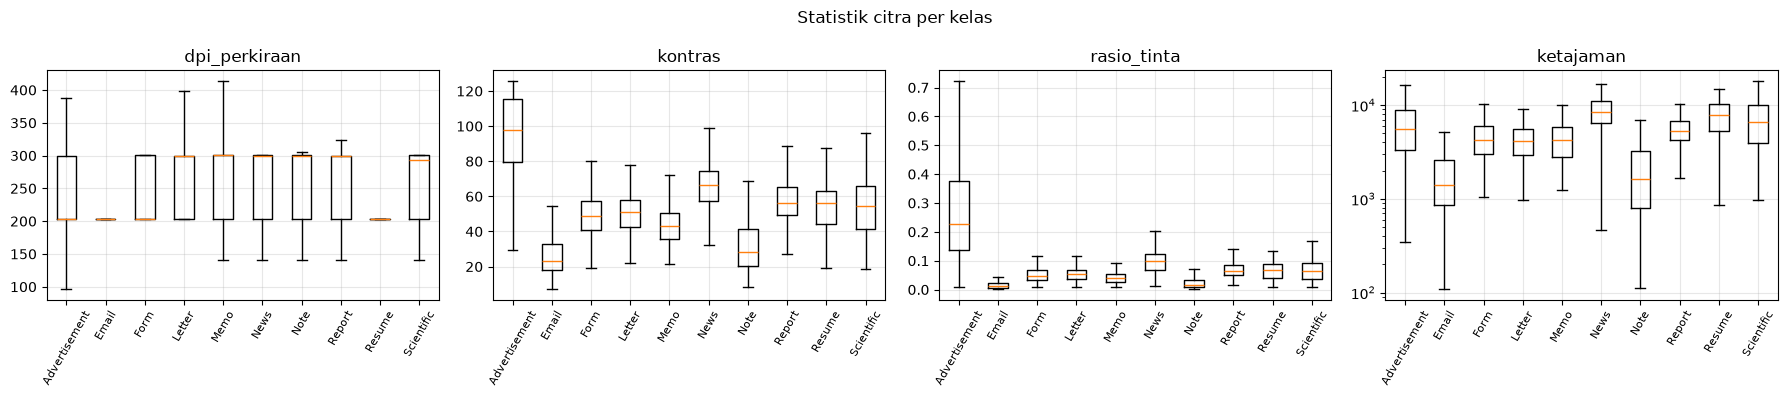

In [43]:
cache_img, cache_thumb = CONFIG["data_interim"] / "eda_citra.csv", CONFIG["data_interim"] / "eda_thumb64.npy"
if cache_img.exists() and cache_thumb.exists() and not RUN["overwrite"]:
    img_stats, thumbs = pd.read_csv(cache_img), np.load(cache_thumb)
else:
    rows, thumbs = EDA.scan_images(manifest["path_citra"].tolist(), RUN["stats_width"])
    img_stats = pd.DataFrame(rows)
    img_stats.to_csv(cache_img, index=False)
    np.save(cache_thumb, thumbs)
img_stats["kelas"] = y_name
display(img_stats.drop(columns="kelas").describe().round(2))
show(P.boxes_by_class(img_stats, ["dpi_perkiraan", "kontras", "rasio_tinta", "ketajaman"],
                      CLASSES, log_cols=("ketajaman",), title="Statistik citra per kelas"),
     "eda_statistik_citra")

### 4.3 Modalitas teks (QS-OCR, acuan)

Panjang teks, bagian kata di luar daftar kata bahasa Inggris (OOV, batas bawah galat OCR),
kode ID arsip, dan kata khas tiap kelas (TF-IDF, dipasang pada bagian latih saja).

,n_kata,n_kata_alfabet,oov,n_kode_id
count,3482.000,3482.000,3429.000,3482.000
mean,223.871,212.039,0.098,0.411
std,200.950,196.456,0.137,0.950
min,0.000,0.000,0.000,0.000
25%,88.000,80.000,0.025,0.000
50%,174.000,160.000,0.055,0.000
75%,293.000,281.000,0.111,1.000
max,1579.000,1573.000,1.000,37.000


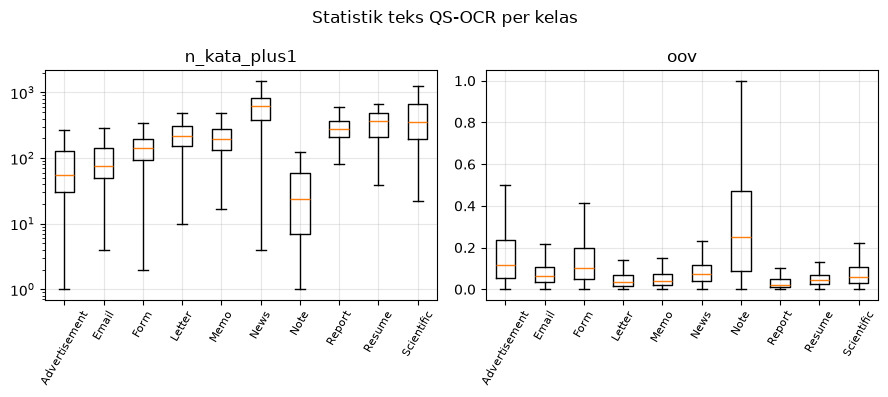

teks kosong: 1.1% | > 500 kata (akan dipotong): 7.8%


,kata khas (TF-IDF)
Advertisement,"warning, surgeon, cigarette, general, advertis..."
Email,"sent, subject, message, original, wednesday, d..."
Form,"date, fax, number, pages, form, total, morris,..."
Letter,"tobacco, dear, research, new, sincerely, york,..."
Memo,"correspondence, attached, philip, morris, memo..."
News,"said, smoking, health, smoke, tobacco, smokers..."
Note,"desk, information, james, ore, web, ous, chris..."
Report,"tobacco, smoking, cigarette, products, product..."
Resume,"university, research, biology, assistant, prof..."
Scientific,"cell, cells, research, results, study, induced..."


In [44]:
known = OCR.known_words()
qs_texts = [Path(p).read_text(encoding="utf-8", errors="replace") for p in manifest["path_teks"]]
txt_stats = pd.DataFrame(EDA.text_stats(qs_texts, known))
txt_stats["kelas"] = y_name
display(txt_stats.drop(columns="kelas").describe().round(3))
txt_stats["n_kata_plus1"] = txt_stats["n_kata"] + 1
show(P.boxes_by_class(txt_stats, ["n_kata_plus1", "oov"], CLASSES, log_cols=("n_kata_plus1",),
                      title="Statistik teks QS-OCR per kelas"), "eda_statistik_teks")
print(f"teks kosong: {(txt_stats.n_kata_alfabet == 0).mean():.1%} | "
      f"> {CONFIG['max_words']} kata (akan dipotong): {(txt_stats.n_kata > CONFIG['max_words']).mean():.1%}")

fit_idx = np.array(sorted(sp["train"] + sp["val"]))
test_idx = np.array(sp["test"])
terms = pd.Series(EDA.top_terms(qs_texts, y_name, fit_idx, CLASSES), name="kata khas (TF-IDF)")
display(terms.to_frame())
terms.to_csv(REPORTS / "eda_kata_khas_per_kelas.csv")

### 4.4 Kurasi: dokumen bermasalah, duplikat, kebocoran split, jalan pintas kode ID

Dokumen **ditandai, tidak dibuang**: derau OCR adalah objek penelitian. Ambang diambil dari
ekor distribusi data (`flag_percentile`), bukan angka karangan. Duplikat = thumbnail
berkorelasi tinggi **dan** teks OCR mirip. Kebocoran = satu anggota pasangan duplikat di
latih/val dan pasangannya di uji. Jalan pintas = seberapa jauh kode ID arsip saja bisa
menebak kelas (Larson et al.).

In [45]:
cur_in = txt_stats.drop(columns=["kelas", "n_kata_plus1"]).join(img_stats.drop(columns="kelas"))
curated, cinfo = EDA.curate(cur_in, thumbs, qs_texts, splits, RUN["flag_percentile"],
                            RUN["dup_min_corr"], RUN["dup_min_jaccard"])
print("ambang dari data:", {k: round(v, 3) for k, v in cinfo["ambang"].items()})
print(f"kandidat duplikat dari citra: {cinfo['kandidat_citra']} | terkonfirmasi teks: "
      f"{len(cinfo['pasangan_duplikat'])} | pasangan bocor per seed: {cinfo['pasangan_bocor']}")

flags = [c for c in curated.columns if c.startswith("flag_")]
flag_by_class = (curated[flags].groupby(y_name).mean() * 100).reindex(CLASSES).round(1)
flag_by_class.loc["SEMUA"] = (curated[flags].mean() * 100).round(1)
display(flag_by_class)

text_bad = curated.flag_teks_kosong | curated.flag_teks_pendek | curated.flag_oov_tinggi
image_bad = curated.flag_resolusi_rendah | curated.flag_buram
cross = pd.DataFrame({"teks bermasalah, citra baik": text_bad & ~image_bad,
                      "citra bermasalah, teks baik": image_bad & ~text_bad,
                      "keduanya bermasalah": text_bad & image_bad}).groupby(y_name).sum().reindex(CLASSES)
print("Dokumen yang hanya satu modalitasnya bermasalah (tempat fusi seharusnya menolong):")
display(cross)

curated["prefiks_kode_id"] = [EDA.id_prefix(t) for t in qs_texts]
majority = float((y_name[test_idx] == pd.Series(y_name[fit_idx]).mode()[0]).mean())
shortcut = pd.DataFrame([
    {"fitur": "3 digit awal kode ID di teks OCR",
     **EDA.shortcut_probe(curated["prefiks_kode_id"].to_numpy(), y_name, fit_idx, test_idx)},
    {"fitur": "3 karakter awal ID berkas",
     **EDA.shortcut_probe(manifest["id"].str[:3].to_numpy(), y_name, fit_idx, test_idx)},
]).round(4)
shortcut["kelas_mayoritas"] = round(majority, 4)
display(shortcut)

out = manifest[["id", "kelas", "path_citra", "path_teks"]].copy()
for s, spl in splits.items():
    col = np.empty(N, dtype=object)
    for part in ("train", "val", "test"):
        col[spl[part]] = part
    out[f"split_s{s}"] = col
pd.concat([out, curated], axis=1).to_csv(CONFIG["data_processed"] / "manifest_kurasi.csv", index=False)
flag_by_class.to_csv(REPORTS / "eda_flag_per_kelas.csv")
shortcut.to_csv(REPORTS / "eda_jalan_pintas_kode_id.csv", index=False)

ambang dari data: {'teks_pendek_maks_kata': 23.0, 'oov_tinggi_min': 0.369, 'resolusi_rendah_maks_dpi': 203.294, 'buram_maks_ketajaman': 788.36}
kandidat duplikat dari citra: 12 | terkonfirmasi teks: 12 | pasangan bocor per seed: {42: 1, 43: 5, 44: 4}


,flag_teks_kosong,flag_teks_pendek,flag_oov_tinggi,flag_resolusi_rendah,flag_buram,flag_duplikat
Advertisement,3.5,17.4,13.0,3.9,2.2,2.6
Email,0.0,4.2,0.2,0.0,19.9,0.3
Form,0.0,1.4,10.7,0.0,0.0,0.0
Letter,0.0,0.2,0.2,0.0,0.0,0.0
Memo,0.0,0.2,0.6,6.5,0.0,0.0
News,0.0,2.1,8.0,3.7,0.5,0.5
Note,14.4,41.3,30.8,2.0,24.9,0.0
Report,0.0,0.0,1.5,1.9,0.0,0.0
Resume,0.0,0.0,0.0,1.7,0.0,0.0
Scientific,0.0,1.1,3.4,0.4,0.0,0.0


Dokumen yang hanya satu modalitasnya bermasalah (tempat fusi seharusnya menolong):


,"teks bermasalah, citra baik","citra bermasalah, teks baik",keduanya bermasalah
Advertisement,62,7,7
Email,0,94,25
Form,48,0,0
Letter,2,0,0
Memo,3,38,2
News,15,7,1
Note,101,5,47
Report,4,5,0
Resume,0,2,0
Scientific,12,1,0


,fitur,oa,macro_f1,kelas_mayoritas
0,3 digit awal kode ID di teks OCR,0.2782,0.1438,0.1782
1,3 karakter awal ID berkas,0.4720,0.2757,0.1782


## 5. OCR multi-mesin (variabel bebas 1)

Setiap mesin membaca **citra JPG yang sama** dan menulis satu JSON per halaman (teks
dalam urutan baca + kotak posisi untuk tahap tata letak nanti) ke `data/interim/ocr/<mesin>/`.
Satu proses per mesin, bisa dilanjutkan: halaman yang sudah ada dilewati.

- **Tesseract**: `--oem 1 --psm 3 -l eng`, sama dengan QS-OCR; biner dipasang lewat winget di Windows.
- **EasyOCR**: dipasang dengan *constraints* agar numpy/torch tidak ikut berubah.
- **PaddleOCR**: venv terpisah `.venv-paddle` (pin numpy-nya bentrok dengan torch).

Catatan: Tesseract-JPG ≠ QS-OCR. Versi (5 vs 4-beta) **dan** sumber citra (JPG vs TIF)
sama-sama berbeda, jadi selisih keduanya adalah efek gabungan.

In [46]:
pins = SE.pin_file(CONFIG["data_interim"] / "constraints_ocr.txt")
if RUN["run_ocr"]:
    %pip install -q pytesseract easyocr -c "{pins}"
    TESS = OCR.find_tesseract() if "tesseract" in RUN["ocr_engines"] else None
    if "tesseract" in RUN["ocr_engines"] and not TESS:
        raise RuntimeError("Tesseract tidak ditemukan. Windows: https://github.com/UB-Mannheim/tesseract/wiki ; "
                           "macOS: brew install tesseract ; Linux: apt install tesseract-ocr. "
                           "Atau hapus 'tesseract' dari RUN['ocr_engines'].")
    PADDLE_PY = OCR.ensure_paddle_venv(ROOT) if "paddleocr" in RUN["ocr_engines"] else None
    GPU = torch.cuda.is_available()
    print("tesseract:", TESS, "| paddle python:", PADDLE_PY, "| EasyOCR GPU:", GPU)


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
tesseract: C:\Program Files\Tesseract-OCR\tesseract.EXE | paddle python: e:\TESIS\apdam-project\apdm-document-classification\.venv-paddle\Scripts\python.exe | EasyOCR GPU: True


In [47]:
MANIFEST = CONFIG["data_processed"] / "manifest.csv"
OCR_DIR = CONFIG["ocr_dir"]

def run_engine(engine, limit=None):
    return OCR.run_engine_subprocess(
        engine, MANIFEST, OCR_DIR, ROOT, limit=limit, gpu=GPU, tesseract_cmd=TESS,
        python=str(PADDLE_PY) if engine == "paddleocr" else None,
        paddle_models=RUN["paddle_models"])

if RUN["run_ocr"]:
    for engine in RUN["ocr_engines"]:
        print(f"\n=== {engine}: uji coba {RUN['ocr_trial_pages']} halaman")
        run_engine(engine, RUN["ocr_trial_pages"])
    est = pd.DataFrame({e: {"dtk/halaman": OCR.seconds_per_page(OCR_DIR, e)} for e in RUN["ocr_engines"]}).T
    est["perkiraan penuh (jam)"] = est["dtk/halaman"] * N / 3600
    display(est.round(2))

    t0 = time.perf_counter()
    for engine in RUN["ocr_engines"]:
        print(f"\n=== {engine}: penuh")
        print(run_engine(engine))
    print(f"OCR selesai dalam {(time.perf_counter() - t0) / 3600:.2f} jam")


=== tesseract: uji coba 20 halaman
[tesseract] 20 dokumen, 20 sudah ada, 0 dikerjakan

=== easyocr: uji coba 20 halaman
[easyocr] 20 dokumen, 20 sudah ada, 0 dikerjakan

=== paddleocr: uji coba 20 halaman
[paddleocr] 20 dokumen, 20 sudah ada, 0 dikerjakan


,dtk/halaman,perkiraan penuh (jam)
tesseract,1.45,1.40
easyocr,32.15,31.10
paddleocr,6.99,6.76



=== tesseract: penuh
[tesseract] 3482 dokumen, 3482 sudah ada, 0 dikerjakan
{'engine': 'tesseract', 'dikerjakan': 0, 'galat': 0, 'detik_per_halaman': 0.0}

=== easyocr: penuh
[easyocr] 3482 dokumen, 3482 sudah ada, 0 dikerjakan
{'engine': 'easyocr', 'dikerjakan': 0, 'galat': 0, 'detik_per_halaman': 0.0}

=== paddleocr: penuh
[paddleocr] 3482 dokumen, 3482 sudah ada, 0 dikerjakan
{'engine': 'paddleocr', 'dikerjakan': 0, 'galat': 0, 'detik_per_halaman': 0.0}
OCR selesai dalam 0.01 jam


In [48]:
# Teks per kondisi, sejajar dengan manifest. Halaman yang hilang = berhenti.
texts = {}
for cond in CONDITIONS:
    texts[cond], missing = OCR.condition_texts(cond, manifest["id"].tolist(),
                                               manifest["path_teks"].tolist(), OCR_DIR)
    assert not missing, (f"{cond}: {len(missing)} halaman belum di-OCR (mis. {missing[:3]}). "
                         "Jalankan bagian OCR sampai tuntas; prosesnya bisa dilanjutkan.")
meta = {e: json.loads((OCR_DIR / e / "_meta.json").read_text()) for e in CONDITIONS[1:]
        if (OCR_DIR / e / "_meta.json").exists()}
(REPORTS / "ocr_meta.json").write_text(json.dumps(meta, indent=1))

i0 = 0
print(f"Dokumen {manifest.id[i0]} ({manifest.kelas[i0]}), 300 karakter pertama per kondisi:")
for cond in CONDITIONS:
    print(f"\n--- {cond} ---\n{texts[cond][i0][:300]}")

Dokumen 0000136188 (Advertisement), 300 karakter pertama per kondisi:

--- qs-ocr ---




A Mpertant as yar
sesiye teaetered cabiieess. Baely
doesn’) keow bea te
Bitton Aau-Fotne bl resin syste. Cant
viduiiliy crafted. Parenter
tiott, Most eapennese liste rn siichinng
Holimars. Costlicr of course



“Has Oetenined -
Wainy: Thy
ie Hoel? h.
That Cia
Marg a Féme awe ii na eager ref Hizo

--- tesseract ---
AS MpeTtant as yan
eostye teteteted cabaceos. Baek
Biron Aau-Fotne bl retin systaa. Cant
Hae mncit is soo muc
doesn’) know how tc
viduilis crafted. Patente.
Heolimars. Costlior of course
“Has Determined :
YourHealth, ae
arg ae Lime aes ies ni eget Misi ay ol
6P9S%0099
iy
et

--- easyocr ---
[ARE
Regist
243562
SmEe}
I# I)fx ;1 Muc ; b#" S!mkethallll ; Mf T[,;t I5i" f,1.t,i
h w"n kr;ane: iv'#' t . [1I K . I:{'Te" / ;ls; F;-T`` 4tt M:
FI %/il;_ rt ', 1'Jidi : Fift:? 'n-]t, vfiM1/ '/n: 'u
[iI/1 _ Afl %"jfi  LN Mkid
H:la;urn , (stli-T of &t se_ L
Wainin Thp Seta,jh} G2mvt Has Detirmninied
T



### 5.1 EDA OCR: proksi kualitas dan kesepakatan antar-mesin

Tobacco3482 tidak punya transkripsi acuan, jadi CER tidak bisa dihitung. Yang dilaporkan
adalah **proksi**: kata terbaca per halaman, halaman kosong, OOV, kecepatan, dan
kesepakatan antar-mesin (median Jaccard himpunan kata). Sepakat tidak berarti benar.

,kata_median,halaman_kosong_persen,oov_median,oov_rata2,dtk_per_halaman
ocr,,,,,
qs-ocr,160.0,1.0626,0.0548,0.0981,NaN
tesseract,161.0,0.6031,0.0573,0.1145,1.4510
easyocr,157.0,0.1723,0.1356,0.2318,32.1510
paddleocr,162.0,0.0574,0.0541,0.1245,6.9875


,qs-ocr,tesseract,easyocr,paddleocr
qs-ocr,1.000,0.920,0.693,0.864
tesseract,0.920,1.000,0.692,0.864
easyocr,0.693,0.692,1.000,0.734
paddleocr,0.864,0.864,0.734,1.000


ocr,qs-ocr,tesseract,easyocr,paddleocr
kelas,,,,
Advertisement,0.119,0.167,0.373,0.191
Email,0.062,0.062,0.096,0.053
Form,0.102,0.125,0.262,0.116
Letter,0.036,0.036,0.107,0.036
Memo,0.040,0.041,0.085,0.032
News,0.075,0.080,0.394,0.102
Note,0.250,0.293,0.636,0.345
Report,0.021,0.023,0.086,0.019
Resume,0.044,0.043,0.109,0.047


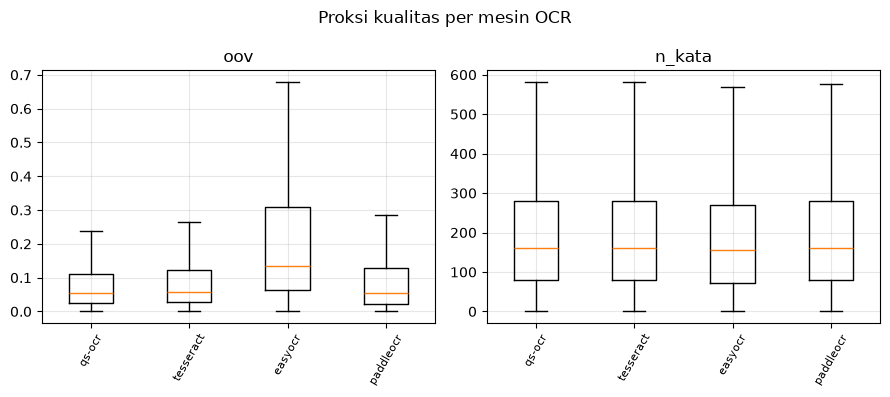

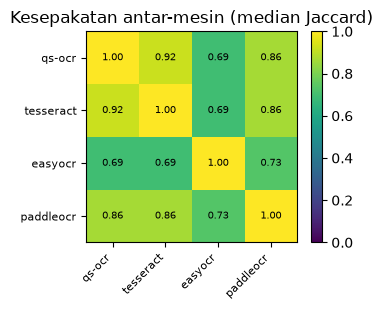

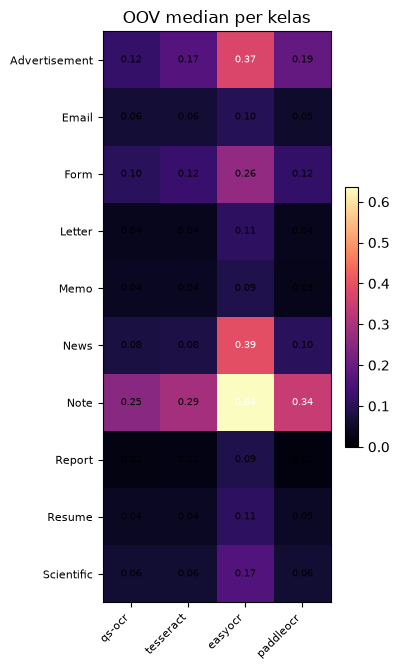

In [49]:
qual = pd.DataFrame(OCR.quality_rows(texts, manifest["id"].tolist(), labels, known))
summary_ocr = qual.groupby("ocr", sort=False).agg(
    kata_median=("n_kata", "median"), halaman_kosong_persen=("n_kata", lambda s: 100 * (s == 0).mean()),
    oov_median=("oov", "median"), oov_rata2=("oov", "mean")).reindex(CONDITIONS)
summary_ocr["dtk_per_halaman"] = [OCR.seconds_per_page(OCR_DIR, c) if c != "qs-ocr" else np.nan
                                  for c in CONDITIONS]
display(summary_ocr.round(4))

agree = OCR.agreement(texts)
agree_m = pd.DataFrame([[agree[(a, b)] for b in CONDITIONS] for a in CONDITIONS],
                       index=CONDITIONS, columns=CONDITIONS)
display(agree_m.round(3))
oov_class = qual.pivot_table(index="kelas", columns="ocr", values="oov", aggfunc="median").reindex(CLASSES)[CONDITIONS]
display(oov_class.round(3))

show(P.boxes_by_class(qual, ["oov", "n_kata"], CONDITIONS, by="ocr",
                      title="Proksi kualitas per mesin OCR"), "ocr_proksi_kualitas")
show(P.heatmap(agree_m.values, CONDITIONS, CONDITIONS, "Kesepakatan antar-mesin (median Jaccard)"),
     "ocr_kesepakatan")
show(P.heatmap(oov_class.values, CONDITIONS, CLASSES, "OOV median per kelas", vmax=float(np.nanmax(oov_class.values)),
               cmap="magma"), "ocr_oov_per_kelas")
qual.to_csv(REPORTS / "ocr_proksi_per_dokumen.csv", index=False)
summary_ocr.to_csv(REPORTS / "ocr_ringkasan.csv")
agree_m.to_csv(REPORTS / "ocr_kesepakatan.csv")
oov_class.to_csv(REPORTS / "ocr_oov_per_kelas.csv")

## 6. Fitur teks per kondisi OCR

Tokenisasi spaCy (tanda baca dibuang), lalu vektor FastText **subword** `cc.en.300.bin`
(± 7 GB di disk, ± 15 GB di RAM; diunduh sekali). Satu berkas
`sequences_<kondisi>.npy` berukuran 3482 × 500 × 300 float16 (± 1 GB) per kondisi.
**Teks masuk mentah**: angka, *stopword*, dan tanda baca tidak dibuang (beda dengan
Kanchi/Kashyap), supaya efek mesin OCR tidak tercampur efek praproses.

In [50]:
import gc

t0 = time.perf_counter()
tokenize = TF.spacy_tokenizer()
feats = TF.build_condition_sequences(texts, tokenize, TF.fasttext_embedder, CONFIG["fase2_data"],
                                     overwrite=RUN["overwrite"])
gc.collect()   # model FastText (± 15 GB) dilepas begitu fungsi selesai
print(f"fitur teks selesai dalam {(time.perf_counter() - t0) / 60:.1f} menit")

tok = pd.DataFrame({c: {"token_median": int(np.median(f["n_token"])),
                        "dokumen_tanpa_token_persen": 100 * (f["n_token"] == 0).mean(),
                        f"di_atas_{CONFIG['max_words']}_persen": 100 * (f["n_token"] > CONFIG["max_words"]).mean(),
                        "ukuran_gb": f["path"].stat().st_size / 1e9} for c, f in feats.items()}).T
display(tok.round(2))
tok.to_csv(REPORTS / "fitur_teks_per_kondisi.csv")

fitur teks selesai dalam 6.9 menit


,token_median,dokumen_tanpa_token_persen,di_atas_500_persen,ukuran_gb
qs-ocr,175.0,0.78,7.96,1.04
tesseract,177.0,0.32,7.87,1.04
easyocr,176.0,0.00,7.35,1.04
paddleocr,179.0,0.00,7.96,1.04


### 6.1 EDA lanjutan: keterpisahan kelas per modalitas

*Linear probe* (regresi logistik) dan t-SNE di atas fitur yang **belum dilatih** pada data
kita: MobileNetV2 ImageNet untuk citra, rata-rata vektor FastText untuk teks tiap kondisi
OCR. Ini memperkirakan seberapa banyak informasi kelas yang dibawa tiap modalitas sebelum
training, dan kelas mana yang lebih dipisahkan teks atau citra.

,fitur,oa_probe,macro_f1_probe,kelas_mayoritas
0,citra (MobileNetV2 pretrained),0.7293,0.7099,0.1782
1,teks qs-ocr (rata-rata FastText),0.6685,0.6491,0.1782
2,teks tesseract (rata-rata FastText),0.6499,0.6231,0.1782
3,teks easyocr (rata-rata FastText),0.6521,0.6212,0.1782
4,teks paddleocr (rata-rata FastText),0.6864,0.6653,0.1782


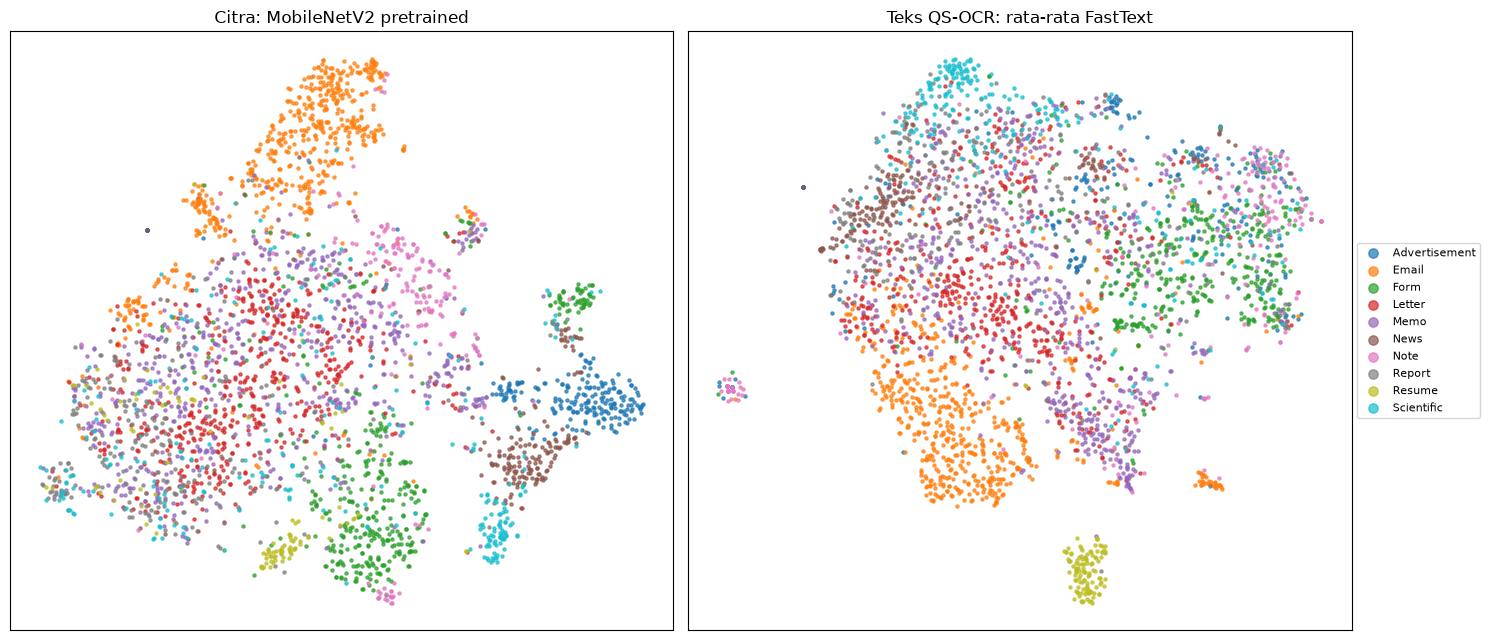

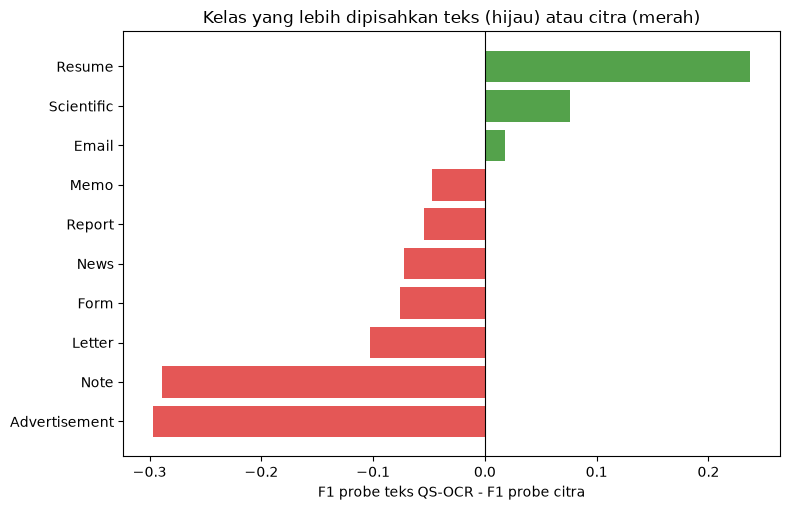

In [51]:
cache = CONFIG["data_interim"] / "eda_cnn_mobilenetv2.npy"
if cache.exists() and not RUN["overwrite"]:
    f_img = np.load(cache)
else:
    f_img = EDA.pretrained_image_features(manifest["path_citra"].tolist(),
                                          num_workers=CONFIG["num_workers"])
    np.save(cache, f_img)

f_txt = {}
for cond, f in feats.items():
    seq = np.load(f["path"], mmap_mode="r")
    f_txt[cond] = np.concatenate([EDA.mean_nonzero_rows(seq[i:i + 256]) for i in range(0, N, 256)])
    del seq

probe_rows, f1_rows = [], {}
r, f1_rows["citra (MobileNetV2 pretrained)"] = EDA.probe(f_img, y_name, fit_idx, test_idx, CLASSES)
probe_rows.append({"fitur": "citra (MobileNetV2 pretrained)", **r})
for cond in CONDITIONS:
    r, f1_rows[f"teks {cond}"] = EDA.probe(f_txt[cond], y_name, fit_idx, test_idx, CLASSES)
    probe_rows.append({"fitur": f"teks {cond} (rata-rata FastText)", **r})
probe_table = pd.DataFrame(probe_rows).round(4)
probe_table["kelas_mayoritas"] = round(majority, 4)
display(probe_table)
probe_table.to_csv(REPORTS / "eda_probe_fitur.csv", index=False)

show(P.scatter_2d({"Citra: MobileNetV2 pretrained": EDA.tsne_2d(f_img, 42, RUN["tsne_perplexity"]),
                   "Teks QS-OCR: rata-rata FastText": EDA.tsne_2d(f_txt["qs-ocr"], 42, RUN["tsne_perplexity"])},
                  y_name, CLASSES), "eda_tsne")

comp = pd.DataFrame(f1_rows, index=CLASSES)
diff = comp["teks qs-ocr"] - comp["citra (MobileNetV2 pretrained)"]
show(P.signed_bars(diff, "Kelas yang lebih dipisahkan teks (hijau) atau citra (merah)",
                   "F1 probe teks QS-OCR - F1 probe citra"), "eda_komplementaritas")
comp.round(3).to_csv(REPORTS / "eda_f1_probe_per_kelas.csv")

## 7. Training unimodal

- **IMAGE**: MobileNetV2 (ImageNet, *fine-tune* penuh), 384×384, satu model per seed.
- **TEXT**: CNN 1D (4 lapis, kernel 12, 512 kanal) di atas sekuens FastText, satu model
  per kondisi OCR × seed.

SGD momentum 0,9, lr 0,01, batch 40 (paper), *early stopping* pada val (deviasi kita).
Setiap model menyimpan keluaran untuk **semua** dokumen (fitur, logit, dan keluaran untuk
masukan kosong) ke `data/processed/fase2/outputs/`. Model yang sudah punya berkas itu
dilewati, jadi bagian ini aman dijalankan ulang setelah terputus.

Sel pertama memperkirakan durasi dari 2 epoch percobaan per jenis model.

In [52]:
transform = build_transform()
paths = manifest["path_citra"].tolist()
blank_img = torch.zeros(1, 3, CONFIG["image_size"], CONFIG["image_size"])
blank_txt = torch.zeros(1, CONFIG["embedding_dim"], CONFIG["max_words"])

def image_ds(idx):
    return DS.ImageDataset(paths, y, idx, transform)

def text_ds_for(cond):
    return lambda idx: DS.SequenceDataset(feats[cond]["path"], y, idx)

jobs = [(EX.IMAGE, s, lambda: ImageBranch(pretrained=True), image_ds, blank_img, "image") for s in SEEDS]
jobs += [(EX.text_name(c), s, CNN1D, text_ds_for(c), blank_txt, "text") for c in CONDITIONS for s in SEEDS]
todo = [j for j in jobs if RUN["overwrite"] or not EX.output_path(j[0], j[1]).exists()]
print(f"{len(jobs)} model unimodal, {len(todo)} belum dilatih")

if todo:
    est = {}
    for kind, build, ds in (("image", lambda: ImageBranch(pretrained=True), image_ds),
                            ("text", CNN1D, text_ds_for(CONDITIONS[0]))):
        if any(j[5] == kind for j in todo):
            loaders = DS.make_loaders(ds, sp)
            est[kind] = T.estimate_duration(build(), loaders, CONFIG["epochs"][kind], device=device)
            DS.close_datasets(*(l.dataset for l in loaders.values()))
    hours = sum(est[j[5]]["perkiraan_jam"] for j in todo)
    print(json.dumps(est, indent=1))
    print(f"\nPerkiraan BATAS ATAS {hours:.1f} jam untuk {len(todo)} model "
          f"(early stopping biasanya memangkasnya).")

15 model unimodal, 0 belum dilatih


In [53]:
unimodal = []
if RUN["run_training"]:
    t0 = time.perf_counter()
    for name, seed, build, ds, blank, kind in jobs:
        print(f"\n[{name} seed {seed}]")
        meta = EX.train_unimodal(name, seed, splits[seed], build, ds, blank,
                                 epochs=CONFIG["epochs"][kind], n_total=N, device=device)
        out = EX.load_outputs(name, seed)
        te = splits[seed]["test"]
        unimodal.append({**meta, **EX.scores(y[te], out["logit"][te].argmax(1))})
        print(f"  test OA {unimodal[-1]['oa']:.4f} | macro-F1 {unimodal[-1]['macro_f1']:.4f}"
              + (" (dari cache)" if meta["dari_cache"] else ""))
    print(f"\nbagian training selesai dalam {(time.perf_counter() - t0) / 3600:.2f} jam")
    unimodal = pd.DataFrame(unimodal)
    display(unimodal[["nama", "seed", "oa", "macro_f1", "best_epoch", "epochs_run", "durasi_detik", "dari_cache"]])
    unimodal.to_csv(REPORTS / "unimodal_per_seed.csv", index=False)
else:
    print("RUN['run_training'] = False -> berhenti sebelum training.")


[IMAGE seed 42]
  test OA 0.8315 | macro-F1 0.8119 (dari cache)

[IMAGE seed 43]
  test OA 0.8386 | macro-F1 0.8124 (dari cache)

[IMAGE seed 44]
  test OA 0.7808 | macro-F1 0.7397 (dari cache)

[TEXT-qs-ocr seed 42]
  test OA 0.7345 | macro-F1 0.7090 (dari cache)

[TEXT-qs-ocr seed 43]
  test OA 0.7248 | macro-F1 0.6994 (dari cache)

[TEXT-qs-ocr seed 44]
  test OA 0.7204 | macro-F1 0.6967 (dari cache)

[TEXT-tesseract seed 42]
  test OA 0.6913 | macro-F1 0.6564 (dari cache)

[TEXT-tesseract seed 43]
  test OA 0.7028 | macro-F1 0.6639 (dari cache)

[TEXT-tesseract seed 44]
  test OA 0.6969 | macro-F1 0.6437 (dari cache)

[TEXT-easyocr seed 42]
  test OA 0.7155 | macro-F1 0.6853 (dari cache)

[TEXT-easyocr seed 43]
  test OA 0.7081 | macro-F1 0.6750 (dari cache)

[TEXT-easyocr seed 44]
  test OA 0.7230 | macro-F1 0.6982 (dari cache)

[TEXT-paddleocr seed 42]
  test OA 0.7498 | macro-F1 0.7119 (dari cache)

[TEXT-paddleocr seed 43]
  test OA 0.7573 | macro-F1 0.7243 (dari cache)

[TEXT

,nama,seed,oa,macro_f1,best_epoch,epochs_run,durasi_detik,dari_cache
0,IMAGE,42,0.831469,0.811862,22,37,2920.135,True
1,IMAGE,43,0.838553,0.812365,20,35,2361.265,True
2,IMAGE,44,0.780761,0.739740,11,26,2785.667,True
3,TEXT-qs-ocr,42,0.734526,0.708999,28,43,151.928,True
4,TEXT-qs-ocr,43,0.724832,0.699415,25,40,140.281,True
5,TEXT-qs-ocr,44,0.720358,0.696694,31,46,161.487,True
6,TEXT-tesseract,42,0.691275,0.656385,24,39,169.278,True
7,TEXT-tesseract,43,0.702834,0.663885,32,47,166.219,True
8,TEXT-tesseract,44,0.696868,0.643709,20,35,121.817,True
9,TEXT-easyocr,42,0.715511,0.685318,21,36,126.843,True


## 8. Fusi: dua aturan di atas model unimodal yang sama

Untuk setiap kondisi OCR × seed, dihitung pada set uji yang sama:

| Model | Arti |
|---|---|
| `IMAGE`, `TEXT` | akurasi tiap unimodal |
| `LATE` | argmax rata-rata logit IMAGE dan TEXT (Kashyap), tanpa training |
| `CONCAT` | *head* MLP di atas fitur beku: proyeksi 1280→128 citra ⊕ 128 teks (Audebert); dilatih pada bagian latih, *early stopping* pada val |
| `ORACLE` | benar bila salah satu unimodal benar (batas atas fusi pemilih) |
| `*_tanpa_teks` / `*_tanpa_citra` | uji *missing modality*: modalitas itu diganti keluaran model untuk masukan kosong |

Catatan untuk laporan: CONCAT di sini **bukan** end-to-end seperti Audebert. Kedua cabang
sudah dilatih terpisah lalu dibekukan, supaya perbedaan LATE vs CONCAT murni perbedaan
aturan fusi. *Head* dilatih pada fitur data latih yang juga dipakai melatih unimodal,
jadi ia menilai tiap cabang dari perilaku latihnya (sama seperti pada end-to-end).

fusi selesai dalam 71 detik
Tabel utama — OA rerata ± simpangan baku antar-seed


model,IMAGE,TEXT,LATE,CONCAT,ORACLE
ocr,,,,,
qs-ocr,0.8169 ± 0.0257,0.7266 ± 0.0059,0.8456 ± 0.0221,0.8316 ± 0.0119,0.9023 ± 0.0127
tesseract,0.8169 ± 0.0257,0.6970 ± 0.0047,0.8376 ± 0.0174,0.8349 ± 0.0102,0.8950 ± 0.0086
easyocr,0.8169 ± 0.0257,0.7155 ± 0.0061,0.8538 ± 0.0158,0.8567 ± 0.0034,0.8972 ± 0.0091
paddleocr,0.8169 ± 0.0257,0.7514 ± 0.0043,0.8653 ± 0.0122,0.8674 ± 0.0014,0.9079 ± 0.0105


macro-F1 rerata ± simpangan baku


model,IMAGE,TEXT,LATE,CONCAT,ORACLE
ocr,,,,,
qs-ocr,0.7880 ± 0.0341,0.7017 ± 0.0053,0.8320 ± 0.0232,0.8221 ± 0.0119,0.8881 ± 0.0140
tesseract,0.7880 ± 0.0341,0.6547 ± 0.0083,0.8195 ± 0.0174,0.8238 ± 0.0083,0.8774 ± 0.0068
easyocr,0.7880 ± 0.0341,0.6862 ± 0.0095,0.8364 ± 0.0167,0.8441 ± 0.0015,0.8799 ± 0.0096
paddleocr,0.7880 ± 0.0341,0.7200 ± 0.0057,0.8481 ± 0.0142,0.8524 ± 0.0016,0.8952 ± 0.0094


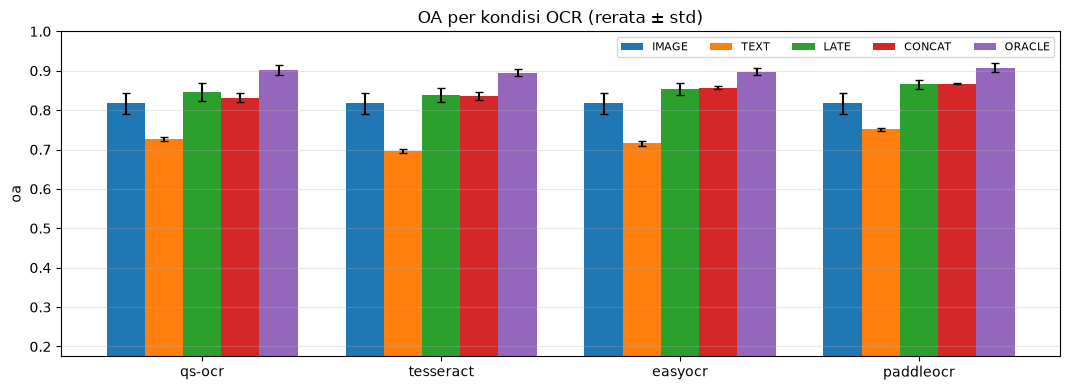

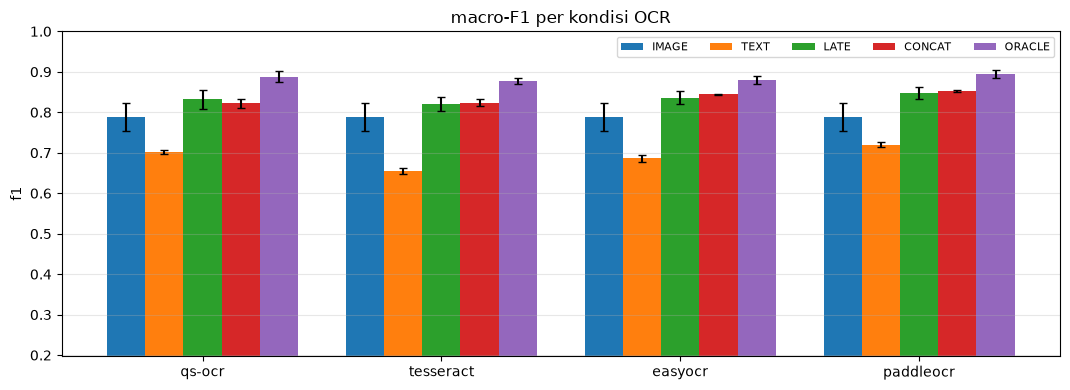

In [54]:
assert RUN["run_training"], "Bagian fusi butuh hasil training (RUN['run_training'] = True)."
t0 = time.perf_counter()
grid, preds = EX.run_grid(y, splits, CONDITIONS, SEEDS)
print(f"fusi selesai dalam {time.perf_counter() - t0:.0f} detik")
summary = EX.summarize(grid)
grid.to_csv(REPORTS / "grid_per_seed.csv", index=False)
summary.to_csv(REPORTS / "grid_ringkasan.csv", index=False)

MAIN = ["IMAGE", "TEXT", "LATE", "CONCAT", "ORACLE"]
fmt = lambda r: f"{r.oa_mean:.4f} ± {r.oa_std:.4f}"
main_table = (summary[summary.model.isin(MAIN)].assign(OA=lambda d: d.apply(fmt, axis=1))
              .pivot(index="ocr", columns="model", values="OA").reindex(CONDITIONS)[MAIN])
print("Tabel utama — OA rerata ± simpangan baku antar-seed")
display(main_table)
f1_table = (summary[summary.model.isin(MAIN)].assign(F1=lambda d: d.apply(lambda r: f"{r.f1_mean:.4f} ± {r.f1_std:.4f}", axis=1))
            .pivot(index="ocr", columns="model", values="F1").reindex(CONDITIONS)[MAIN])
print("macro-F1 rerata ± simpangan baku")
display(f1_table)
main_table.to_csv(REPORTS / "tabel_utama_oa.csv")
f1_table.to_csv(REPORTS / "tabel_utama_f1.csv")
show(P.grouped_bars(summary, MAIN, CONDITIONS, "oa", "OA per kondisi OCR (rerata ± std)"), "grid_oa")
show(P.grouped_bars(summary, MAIN, CONDITIONS, "f1", "macro-F1 per kondisi OCR"), "grid_f1")

In [55]:
# Pemeriksaan kewarasan (rencana Tahap 11): sel QS-OCR x FastText dan IMAGE memakai
# setelan yang sama dengan Fase 1, jadi harus mendekati angka Fase 1 (dijalankan
# 2026-09-30). Selisih besar pada mode penuh berarti ada yang rusak: berhenti, periksa.
FASE1 = {"TEXT": (0.7266, 0.0059), "IMAGE": (0.8086, 0.0210)}
for model, (ref, ref_std) in FASE1.items():
    r = summary[(summary.ocr == "qs-ocr") & (summary.model == model)].iloc[0]
    gap = r.oa_mean - ref
    ok = abs(gap) <= max(0.02, 2 * ref_std)
    print(f"{model:5s} qs-ocr: {r.oa_mean:.4f} ± {r.oa_std:.4f} | Fase 1 {ref:.4f} ± {ref_std:.4f} "
          f"| selisih {gap:+.4f} -> {'OK' if ok else 'MENYIMPANG'}")
    if not ok and not RUN["quick"]:
        print("  PERIKSA sebelum menafsirkan hasil: split, epoch, sekuens QS-OCR, atau micro-batch berbeda?")
if RUN["quick"]:
    print("(mode cepat: epoch dipangkas, selisih besar wajar)")

TEXT  qs-ocr: 0.7266 ± 0.0059 | Fase 1 0.7266 ± 0.0059 | selisih -0.0000 -> OK
IMAGE qs-ocr: 0.8169 ± 0.0257 | Fase 1 0.8086 ± 0.0210 | selisih +0.0083 -> OK


## 9. Uji hipotesis

### H1 — Mesin OCR mengubah akurasi cabang teks

McNemar berpasangan antar-kondisi OCR pada set uji yang sama, untuk `TEXT` (inti H1) dan
untuk kedua aturan fusi (pelengkap). Koreksi Holm dilakukan di dalam tiap seed
(6 pasangan per keluarga). H1 didukung bila selisih yang signifikan konsisten di ketiga seed.

,seed,model,a,b,oa_a,oa_b,hanya_a_benar,hanya_b_benar,p,p_holm,signifikan
0,42,TEXT,qs-ocr,tesseract,0.7345,0.6913,283,167,0.0000,0.0000,True
1,42,TEXT,qs-ocr,easyocr,0.7345,0.7155,289,238,0.0293,0.0586,False
2,42,TEXT,qs-ocr,paddleocr,0.7345,0.7498,187,228,0.0495,0.0586,False
3,42,TEXT,tesseract,easyocr,0.6913,0.7155,232,297,0.0053,0.0160,True
4,42,TEXT,tesseract,paddleocr,0.6913,0.7498,181,338,0.0000,0.0000,True
5,42,TEXT,easyocr,paddleocr,0.7155,0.7498,190,282,0.0000,0.0001,True
6,43,TEXT,qs-ocr,tesseract,0.7248,0.7028,311,252,0.0144,0.0433,True
7,43,TEXT,qs-ocr,easyocr,0.7248,0.7081,313,268,0.0678,0.1357,False
8,43,TEXT,qs-ocr,paddleocr,0.7248,0.7573,216,303,0.0002,0.0006,True
9,43,TEXT,tesseract,easyocr,0.7028,0.7081,262,276,0.5752,0.5752,False


Ringkasan per pasangan (selisih = a - b):


selisih_oa_rata2  seed_signifikan  n_seed
model  a         b                                                   
CONCAT easyocr   paddleocr           -0.0107                1       3
       qs-ocr    easyocr             -0.0251                2       3
                 paddleocr           -0.0358                3       3
                 tesseract           -0.0034                2       3
       tesseract easyocr             -0.0217                2       3
                 paddleocr           -0.0324                3       3
LATE   easyocr   paddleocr           -0.0114                1       3
       qs-ocr    easyocr             -0.0082                1       3
                 paddleocr           -0.0196                2       3
                 tesseract            0.0081                1       3
       tesseract easyocr             -0.0163                2       3
                 paddleocr           -0.0277                3       3
TEXT   easyocr   paddleocr           -0.0359                3       3
       qs-ocr    easyocr              0.0111                0       3
                 paddleocr           -0.0249                2       3
                 tesseract            0.0296                3       3
       tesseract easyocr             -0.0185                2       3
                 paddleocr           -0.0544                3       3

F1 per kelas cabang TEXT (rerata seed)


,qs-ocr,tesseract,easyocr,paddleocr
Advertisement,0.537,0.445,0.537,0.622
Email,0.953,0.950,0.952,0.952
Form,0.718,0.687,0.694,0.747
Letter,0.671,0.669,0.669,0.745
Memo,0.758,0.737,0.761,0.803
News,0.709,0.596,0.659,0.682
Note,0.621,0.565,0.604,0.529
Report,0.495,0.460,0.507,0.546
Resume,0.969,0.946,0.954,0.973
Scientific,0.587,0.491,0.525,0.601


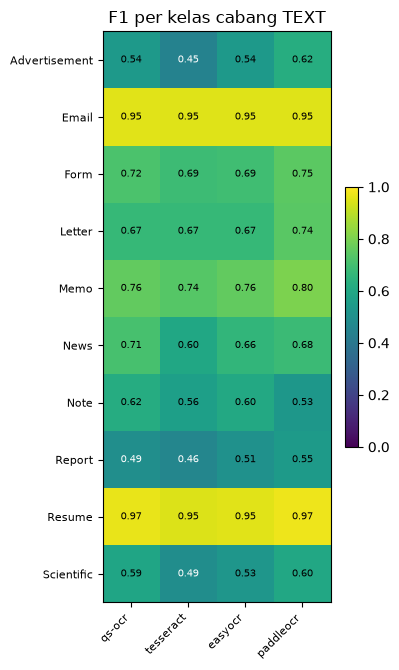

In [56]:
h1 = pd.concat([EX.mcnemar_conditions(preds, m, CONDITIONS, SEEDS) for m in ("TEXT", "LATE", "CONCAT")])
h1.to_csv(REPORTS / "uji_h1_mcnemar_antar_ocr.csv", index=False)
display(h1[h1.model == "TEXT"].round(4))
consistent = (h1.groupby(["model", "a", "b"])
                .agg(selisih_oa_rata2=("oa_a", "mean"), oa_b=("oa_b", "mean"),
                     seed_signifikan=("signifikan", "sum"), n_seed=("seed", "size")))
consistent["selisih_oa_rata2"] -= consistent.pop("oa_b")
print("Ringkasan per pasangan (selisih = a - b):")
display(consistent.round(4))

from sklearn.metrics import f1_score

per_class = {}
for cond in CONDITIONS:
    per_class[cond] = np.mean([f1_score(preds[(cond, s)]["y_true"], preds[(cond, s)]["TEXT"],
                                           labels=range(len(CLASSES)), average=None, zero_division=0)
                               for s in SEEDS], axis=0)
per_class = pd.DataFrame(per_class, index=CLASSES)
print("F1 per kelas cabang TEXT (rerata seed)")
display(per_class.round(3))
per_class.to_csv(REPORTS / "f1_per_kelas_text.csv")
show(P.heatmap(per_class.values, CONDITIONS, CLASSES, "F1 per kelas cabang TEXT", cmap="viridis"),
     "f1_per_kelas_text")

### H3 — Apakah teks yang lebih kuat lebih dipakai, dan aturan mana yang lebih tahan?

`turun_tanpa_teks` = OA fusi − OA fusi dengan teks dikosongkan. H3 didukung bila nilainya
naik seiring OA cabang teks, dan bila LATE kehilangan lebih sedikit daripada CONCAT saat
cabangnya timpang. Juga diuji langsung: McNemar LATE vs CONCAT per kondisi (Holm per seed).

,ocr,seed,oa_text,oa_image,oa_oracle,oa_late,late_turun_tanpa_teks,late_turun_tanpa_citra,oa_concat,concat_turun_tanpa_teks,concat_turun_tanpa_citra
0,easyocr,42,0.7155,0.8315,0.9042,0.8613,0.0339,0.5943,0.8572,0.2476,0.2938
1,easyocr,43,0.7081,0.8386,0.9031,0.8684,0.0321,0.3978,0.8606,0.0839,0.3087
2,easyocr,44,0.7230,0.7808,0.8844,0.8318,0.0474,0.4333,0.8523,0.1991,0.4265
3,paddleocr,42,0.7498,0.8315,0.9154,0.8665,0.0410,0.5209,0.8658,0.3076,0.2558
4,paddleocr,43,0.7573,0.8386,0.9154,0.8796,0.0425,0.2905,0.8673,0.4448,0.1525
5,paddleocr,44,0.7472,0.7808,0.8930,0.8497,0.0694,0.5757,0.8691,0.3013,0.5876
6,qs-ocr,42,0.7345,0.8315,0.9098,0.8609,0.0574,0.5037,0.8475,0.4541,0.1726
7,qs-ocr,43,0.7248,0.8386,0.9128,0.8617,0.0373,0.3177,0.8188,0.7095,0.1518
8,qs-ocr,44,0.7204,0.7808,0.8844,0.8143,0.0574,0.3393,0.8285,0.5694,0.3251
9,tesseract,42,0.6913,0.8315,0.8978,0.8378,0.0194,0.4221,0.8266,0.6447,0.1853


Rerata antar-seed


,oa_text,oa_image,oa_oracle,oa_late,late_turun_tanpa_teks,late_turun_tanpa_citra,oa_concat,concat_turun_tanpa_teks,concat_turun_tanpa_citra
ocr,,,,,,,,,
qs-ocr,0.7266,0.8169,0.9023,0.8456,0.0507,0.3869,0.8316,0.5777,0.2165
tesseract,0.6970,0.8169,0.8950,0.8376,0.0290,0.4116,0.8349,0.6090,0.2726
easyocr,0.7155,0.8169,0.8972,0.8538,0.0378,0.4751,0.8567,0.1769,0.3430
paddleocr,0.7514,0.8169,0.9079,0.8653,0.0510,0.4623,0.8674,0.3512,0.3320


Spearman(OA teks, LATE turun tanpa teks) = 0.683  (n = 12 sel)
Spearman(OA teks, CONCAT turun tanpa teks) = -0.273  (n = 12 sel)


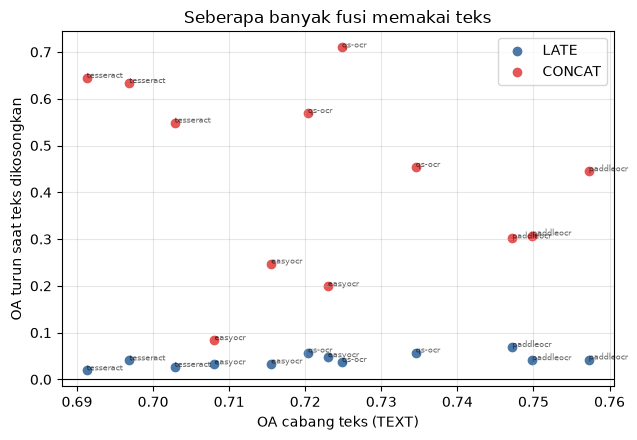

,seed,ocr,a,b,oa_a,oa_b,hanya_a_benar,hanya_b_benar,p,p_holm,signifikan
0,42,qs-ocr,LATE,CONCAT,0.8609,0.8475,87,51,0.0028,0.0110,True
1,42,tesseract,LATE,CONCAT,0.8378,0.8266,128,98,0.0535,0.1605,False
2,42,easyocr,LATE,CONCAT,0.8613,0.8572,88,77,0.4364,0.8727,False
3,42,paddleocr,LATE,CONCAT,0.8665,0.8658,63,61,0.9285,0.9285,False
4,43,qs-ocr,LATE,CONCAT,0.8617,0.8188,196,81,0.0000,0.0000,True
5,43,tesseract,LATE,CONCAT,0.8587,0.8494,100,75,0.0693,0.1387,False
6,43,easyocr,LATE,CONCAT,0.8684,0.8606,94,73,0.1214,0.1387,False
7,43,paddleocr,LATE,CONCAT,0.8796,0.8673,87,54,0.0068,0.0205,True
8,44,qs-ocr,LATE,CONCAT,0.8143,0.8285,98,136,0.0154,0.0308,True
9,44,tesseract,LATE,CONCAT,0.8162,0.8289,127,161,0.0516,0.0516,False


In [57]:
use = EX.modality_use(grid)
use.to_csv(REPORTS / "uji_h3_pemakaian_modalitas.csv", index=False)
display(use.round(4))
use_mean = use.groupby("ocr", sort=False).mean(numeric_only=True).drop(columns="seed").reindex(CONDITIONS)
print("Rerata antar-seed")
display(use_mean.round(4))
for rule in ("late", "concat"):
    rho = use[["oa_text", f"{rule}_turun_tanpa_teks"]].corr(method="spearman").iloc[0, 1]
    print(f"Spearman(OA teks, {rule.upper()} turun tanpa teks) = {rho:.3f}  (n = {len(use)} sel)")
show(P.modality_use_plot(use), "h3_pemakaian_teks")

h3 = EX.mcnemar_models(preds, "LATE", "CONCAT", CONDITIONS, SEEDS)
h3.to_csv(REPORTS / "uji_h3_mcnemar_late_vs_concat.csv", index=False)
display(h3.round(4))

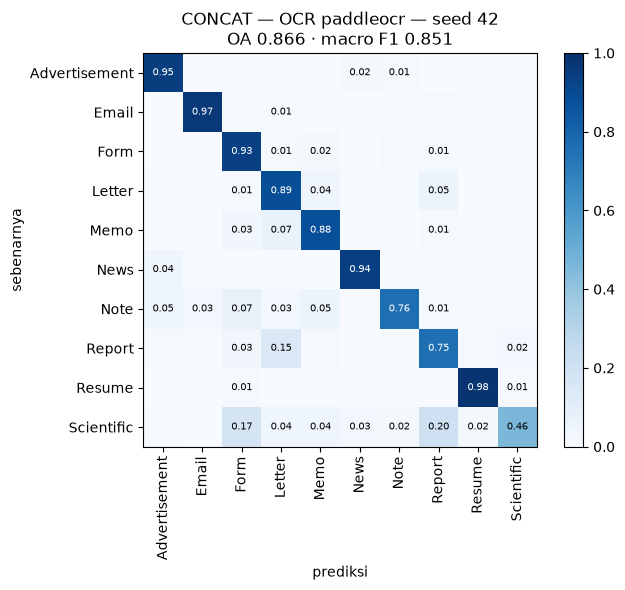

               precision    recall  f1-score   support

Advertisement      0.884     0.949     0.916       177
        Email      0.980     0.967     0.974       461
         Form      0.801     0.934     0.862       332
       Letter      0.818     0.886     0.851       437
         Memo      0.905     0.881     0.893       478
         News      0.919     0.938     0.928       145
         Note      0.901     0.761     0.825       155
       Report      0.655     0.755     0.702       204
       Resume      0.938     0.978     0.957        92
   Scientific      0.902     0.458     0.607       201

     accuracy                          0.866      2682
    macro avg      0.870     0.851     0.851      2682
 weighted avg      0.872     0.866     0.862      2682



In [58]:
# Matriks konfusi sel terbaik (OA LATE/CONCAT tertinggi, rerata seed), seed pertama
best = summary[summary.model.isin(["LATE", "CONCAT"])].sort_values("oa_mean").iloc[-1]
p = preds[(best.ocr, SEEDS[0])]
res = {"y_true": p["y_true"], "y_pred": p[best.model], **EX.scores(p["y_true"], p[best.model])}
show(T.plot_confusion(res, f"{best.model} — OCR {best.ocr} — seed {SEEDS[0]}"), "konfusi_terbaik")
print(T.report(res))

### H3 lanjutan — apakah kejatuhan *missing modality* artefak masukan kosong?

Uji *missing modality* di atas mengganti modalitas dengan keluaran model untuk masukan
kosong. CONCAT tanpa teks jatuh jauh **di bawah IMAGE sendiri**, yang hanya mungkin bila
masukan pengganti keluar distribusi bagi *head*. Dua uji lanjutan (pra-registrasi di
`vault/30-eksperimen/17-missing-modality-lanjutan.md`), keduanya hanya membaca cache
keluaran unimodal, tanpa GPU:

| Model | Arti |
|---|---|
| `*_tanpa_teks_rerata` / `*_tanpa_citra_rerata` | modalitas diganti **rata-rata** fitur (CONCAT) atau logit (LATE) bagian latih: pengganti di dalam distribusi |
| `CONCAT_nonkosong` | *head* dilatih ulang **tanpa** dokumen berteks kosong di latih dan val *head*; set uji tidak berubah |
| `CONCAT_nonkosong_tanpa_teks[_rerata]` | uji tanpa teks pada *head* itu |

"Teks kosong" = fitur teks dokumen sama dengan fitur masukan kosong, yaitu kosong menurut
model (halaman 0 kata, atau semua token terbuang saat tokenisasi).

In [60]:
import importlib
EX = importlib.reload(EX)


In [61]:
t0 = time.perf_counter()
fu, fu_preds = EX.run_grid(y, splits, CONDITIONS, SEEDS, cell=EX.evaluate_followup)
print(f"uji lanjutan selesai dalam {time.perf_counter() - t0:.0f} detik")
fu["kelas_terbanyak"] = [CLASSES[i] for i in fu["kelas_terbanyak"]]
fu.to_csv(REPORTS / "uji_lanjutan_missing_modality.csv", index=False)
print("head CONCAT identik dengan bagian 8:",
      all(np.array_equal(fu_preds[k]["CONCAT"], preds[k]["CONCAT"]) for k in preds))

# Dokumen kosong menurut model, per kelas; cek silang dengan halaman 0 kata (bagian 5.1).
NOTE = CLASSES.index("Note")
empty_by_class = {}
for cond in CONDITIONS:
    masks = [EX.empty_text_mask(EX.load_outputs(EX.text_name(cond), s)) for s in SEEDS]
    print(f"{cond:10s} kosong menurut model: {masks[0].sum():3d} | 0 kata menurut OCR: "
          f"{int((qual[qual.ocr == cond].n_kata == 0).sum()):3d} | sama antar-seed: "
          f"{all(np.array_equal(masks[0], m) for m in masks)}")
    empty_by_class[cond] = pd.Series(y[masks[0]]).map(dict(enumerate(CLASSES))).value_counts()
empty_by_class = pd.DataFrame(empty_by_class).reindex(CLASSES).fillna(0).astype(int)
print(f"Dokumen kosong per kelas (seluruh {len(y)} dokumen)")
display(empty_by_class)
display(fu.groupby(["ocr", "seed"], sort=False)[["n_kosong_latih", "n_kosong_val", "n_kosong_uji"]].first())

uji lanjutan selesai dalam 133 detik
head CONCAT identik dengan bagian 8: True
qs-ocr     kosong menurut model:  27 | 0 kata menurut OCR:  37 | sama antar-seed: True
tesseract  kosong menurut model:  11 | 0 kata menurut OCR:  21 | sama antar-seed: True
easyocr    kosong menurut model:   0 | 0 kata menurut OCR:   6 | sama antar-seed: True
paddleocr  kosong menurut model:   0 | 0 kata menurut OCR:   2 | sama antar-seed: True
Dokumen kosong per kelas (seluruh 3482 dokumen)


,qs-ocr,tesseract,easyocr,paddleocr
Advertisement,7,5,0,0
Email,0,0,0,0
Form,0,0,0,0
Letter,0,0,0,0
Memo,0,0,0,0
News,0,0,0,0
Note,20,6,0,0
Report,0,0,0,0
Resume,0,0,0,0
Scientific,0,0,0,0


,,n_kosong_latih,n_kosong_val,n_kosong_uji
ocr,seed,,,
qs-ocr,42,4,1,22
tesseract,42,2,0,9
easyocr,42,0,0,0
paddleocr,42,0,0,0
qs-ocr,43,8,0,19
tesseract,43,4,0,7
easyocr,43,0,0,0
paddleocr,43,0,0,0
qs-ocr,44,6,1,20


In [62]:
g = grid.pivot_table(index=["ocr", "seed"], columns="model", values="oa")
w = fu.pivot_table(index=["ocr", "seed"], columns="model", values="oa")
fu_delta = pd.DataFrame({
    "LATE_tanpa_teks_kosong-IMAGE": g["LATE_tanpa_teks"] - g["IMAGE"],
    "LATE_tanpa_teks_rerata-IMAGE": w["LATE_tanpa_teks_rerata"] - w["IMAGE"],
    "CONCAT_tanpa_teks_kosong-IMAGE": w["CONCAT_tanpa_teks"] - w["IMAGE"],
    "CONCAT_tanpa_teks_rerata-IMAGE": w["CONCAT_tanpa_teks_rerata"] - w["IMAGE"],
    "CONCAT_nonkosong_tanpa_teks_kosong-IMAGE": w["CONCAT_nonkosong_tanpa_teks"] - w["IMAGE"],
    "CONCAT_nonkosong_tanpa_teks_rerata-IMAGE": w["CONCAT_nonkosong_tanpa_teks_rerata"] - w["IMAGE"],
    "LATE_tanpa_citra_kosong-TEXT": g["LATE_tanpa_citra"] - g["TEXT"],
    "LATE_tanpa_citra_rerata-TEXT": w["LATE_tanpa_citra_rerata"] - w["TEXT"],
    "CONCAT_tanpa_citra_kosong-TEXT": g["CONCAT_tanpa_citra"] - g["TEXT"],
    "CONCAT_tanpa_citra_rerata-TEXT": w["CONCAT_tanpa_citra_rerata"] - w["TEXT"],
    "CONCAT_nonkosong-CONCAT": w["CONCAT_nonkosong"] - w["CONCAT"],
}).reset_index()
fu_delta.to_csv(REPORTS / "uji_lanjutan_selisih.csv", index=False)
fu_delta_mean = fu_delta.groupby("ocr", sort=False).mean(numeric_only=True).drop(columns="seed").reindex(CONDITIONS)
print("Selisih OA terhadap unimodal (rerata seed); per seed di uji_lanjutan_selisih.csv")
display(fu_delta_mean.T.round(4))

# Porsi prediksi Note pada set uji: dugaan "teks kosong => Note" meramalkan porsi ini
# membengkak saat teks kosong dan kembali normal pada head tanpa dokumen kosong.
NOTE_MODELS = ["IMAGE", "CONCAT", "CONCAT_tanpa_teks", "CONCAT_tanpa_teks_rerata",
               "CONCAT_nonkosong_tanpa_teks", "CONCAT_nonkosong_tanpa_teks_rerata"]
note_share = pd.DataFrame([{"ocr": c, "seed": s, "Note_sebenarnya": float((p["y_true"] == NOTE).mean()),
                            **{m: float((p[m] == NOTE).mean()) for m in NOTE_MODELS}}
                           for (c, s), p in fu_preds.items()])
note_share.to_csv(REPORTS / "uji_lanjutan_porsi_note.csv", index=False)
print("Porsi prediksi Note (rerata seed)")
display(note_share.groupby("ocr", sort=False).mean(numeric_only=True).drop(columns="seed").reindex(CONDITIONS).round(4))
print("Kelas terbanyak saat teks kosong (per seed)")
display(fu[fu.model.isin(["CONCAT_tanpa_teks", "CONCAT_nonkosong_tanpa_teks"])]
        .pivot_table(index=["ocr", "seed"], columns="model", values=["kelas_terbanyak", "porsi_kelas_terbanyak"],
                     aggfunc="first").round(3))

Selisih OA terhadap unimodal (rerata seed); per seed di uji_lanjutan_selisih.csv


ocr,qs-ocr,tesseract,easyocr,paddleocr
LATE_tanpa_teks_kosong-IMAGE,-0.0220,-0.0083,-0.0009,-0.0026
LATE_tanpa_teks_rerata-IMAGE,-0.1322,-0.1288,-0.0757,-0.0744
CONCAT_tanpa_teks_kosong-IMAGE,-0.5630,-0.5910,-0.1371,-0.3008
CONCAT_tanpa_teks_rerata-IMAGE,-0.1080,-0.1301,-0.0257,-0.0270
CONCAT_nonkosong_tanpa_teks_kosong-IMAGE,-0.4957,-0.6330,-0.1371,-0.3008
CONCAT_nonkosong_tanpa_teks_rerata-IMAGE,-0.0997,-0.1480,-0.0257,-0.0270
LATE_tanpa_citra_kosong-TEXT,-0.2678,-0.2711,-0.3368,-0.3485
LATE_tanpa_citra_rerata-TEXT,-0.0285,-0.0358,-0.0403,-0.0424
CONCAT_tanpa_citra_kosong-TEXT,-0.1115,-0.1346,-0.2018,-0.2160
CONCAT_tanpa_citra_rerata-TEXT,-0.0045,0.0061,-0.0172,-0.0142


Porsi prediksi Note (rerata seed)


,Note_sebenarnya,IMAGE,CONCAT,CONCAT_tanpa_teks,CONCAT_tanpa_teks_rerata,CONCAT_nonkosong_tanpa_teks,CONCAT_nonkosong_tanpa_teks_rerata
ocr,,,,,,,
qs-ocr,0.0578,0.0529,0.0749,0.7269,0.0718,0.4827,0.0575
tesseract,0.0578,0.0529,0.0670,0.7558,0.0839,0.8167,0.1003
easyocr,0.0578,0.0529,0.0608,0.1924,0.0428,0.1924,0.0428
paddleocr,0.0578,0.0529,0.0567,0.3198,0.0588,0.3198,0.0588


Kelas terbanyak saat teks kosong (per seed)


kelas_terbanyak                    \
model          CONCAT_nonkosong_tanpa_teks CONCAT_tanpa_teks   
ocr       seed                                                 
easyocr   42                          Note              Note   
          43                         Email             Email   
          44                          Memo              Memo   
paddleocr 42                         Email             Email   
          43                          Note              Note   
          44                          Note              Note   
qs-ocr    42                         Email              Note   
          43                          Note              Note   
          44                          News              Note   
tesseract 42                          Note              Note   
          43                          Note              Note   
          44                          Note              Note   

                     porsi_kelas_terbanyak                    
model          CONCAT_nonkosong_tanpa_teks CONCAT_tanpa_teks  
ocr       seed                                                
easyocr   42                         0.255             0.255  
          43                         0.166             0.166  
          44                         0.300             0.300  
paddleocr 42                         0.529             0.529  
          43                         0.532             0.532  
          44                         0.383             0.383  
qs-ocr    42                         0.474             0.463  
          43                         0.892             0.942  
          44                         0.383             0.776  
tesseract 42                         0.743             0.703  
          43                         0.864             0.738  
          44                         0.843             0.826

In [63]:
# Kriteria pra-registrasi (17-missing-modality-lanjutan), dinilai pada rerata seed per kondisi.
d, ns = fu_delta_mean, note_share.groupby("ocr", sort=False).mean(numeric_only=True).reindex(CONDITIONS)
n_empty_train = fu.groupby("ocr", sort=False)["n_kosong_latih"].mean().reindex(CONDITIONS)
h4a = pd.DataFrame({
    "CONCAT_tanpa_teks_rerata_dekat_IMAGE": d["CONCAT_tanpa_teks_rerata-IMAGE"].abs() <= 0.05,
    "LATE_tanpa_citra_rerata_dekat_TEXT": d["LATE_tanpa_citra_rerata-TEXT"] >= -0.05,
    "CONCAT_tanpa_citra_rerata_dekat_TEXT": d["CONCAT_tanpa_citra_rerata-TEXT"] >= -0.05,
})
h4b = pd.DataFrame({
    "n_kosong_latih": n_empty_train,
    "prasyarat_nonkosong_tidak_rusak": d["CONCAT_nonkosong-CONCAT"].abs() <= 0.01,
    "note_membengkak_head_asli": ns["CONCAT_tanpa_teks"] >= ns["Note_sebenarnya"] + 0.10,
    "note_normal_head_nonkosong": ns["CONCAT_nonkosong_tanpa_teks"] <= ns["Note_sebenarnya"] + 0.05,
    "jarak_ke_IMAGE_menyusut_separuh": d["CONCAT_nonkosong_tanpa_teks_kosong-IMAGE"].abs()
                                       <= d["CONCAT_tanpa_teks_kosong-IMAGE"].abs() / 2,
})
print("H4a — pengganti rerata di dalam distribusi")
display(h4a)
print("H4b — 'teks kosong => Note' (bermakna hanya bila n_kosong_latih > 0)")
display(h4b)

H4a — pengganti rerata di dalam distribusi


,CONCAT_tanpa_teks_rerata_dekat_IMAGE,LATE_tanpa_citra_rerata_dekat_TEXT,CONCAT_tanpa_citra_rerata_dekat_TEXT
ocr,,,
qs-ocr,False,True,True
tesseract,False,True,True
easyocr,True,True,True
paddleocr,True,True,True


H4b — 'teks kosong => Note' (bermakna hanya bila n_kosong_latih > 0)


,n_kosong_latih,prasyarat_nonkosong_tidak_rusak,note_membengkak_head_asli,note_normal_head_nonkosong,jarak_ke_IMAGE_menyusut_separuh
ocr,,,,,
qs-ocr,6.000000,True,True,False,False
tesseract,2.666667,True,True,False,False
easyocr,0.000000,True,True,False,False
paddleocr,0.000000,True,True,False,False


## 10. Ringkasan untuk catatan vault

Salin blok di bawah ke `vault/30-eksperimen/` (field Dataview) dan
`vault/50-hasil/`, lalu ubah status `belum-dijalankan` → `selesai`. Semua CSV dan gambar
ada di `reports/fase2/` dan `reports/figures/fase2_*`.

In [64]:
print("deviasi runtime:", deviasi_runtime() or "tidak ada")
print(f"seed:: {SEEDS} | epoch:: {CONFIG['epochs']} | split:: 800 latih (80 val) / {len(sp['test'])} uji\n")
for cond in CONDITIONS:
    print(f"--- OCR {cond} ---")
    for m in MAIN:
        r = summary[(summary.ocr == cond) & (summary.model == m)].iloc[0]
        print(f"  model:: {m:7s} oa:: {r.oa_mean:.4f} ± {r.oa_std:.4f}  macro_f1:: {r.f1_mean:.4f} ± {r.f1_std:.4f}")
print("\nH1 (TEXT, pasangan signifikan per seed):")
print(consistent.loc["TEXT"][["selisih_oa_rata2", "seed_signifikan", "n_seed"]].round(4).to_string())
print("\nH3 (rerata turun tanpa teks):")
print(use_mean[["oa_text", "late_turun_tanpa_teks", "concat_turun_tanpa_teks"]].round(4).to_string())
summary_json = {"main_oa": main_table.to_dict(), "main_f1": f1_table.to_dict(),
                "deviasi": deviasi_runtime(), "seeds": SEEDS, "epochs": CONFIG["epochs"]}
(REPORTS / "ringkasan.json").write_text(json.dumps(summary_json, indent=1, ensure_ascii=False))
print("\ndisimpan: reports/fase2/ringkasan.json")

deviasi runtime: ['batch 40 dipecah jadi micro-batch 8 dengan akumulasi gradien; update optimizer tetap dari 40 sampel, tapi BatchNorm menormalisasi per micro-batch', 'mixed precision (AMP) aktif, tidak dipakai paper']
seed:: [42, 43, 44] | epoch:: {'text': 100, 'image': 200, 'fusion': 200, 'head': 200} | split:: 800 latih (80 val) / 2682 uji

--- OCR qs-ocr ---
  model:: IMAGE   oa:: 0.8169 ± 0.0257  macro_f1:: 0.7880 ± 0.0341
  model:: TEXT    oa:: 0.7266 ± 0.0059  macro_f1:: 0.7017 ± 0.0053
  model:: LATE    oa:: 0.8456 ± 0.0221  macro_f1:: 0.8320 ± 0.0232
  model:: CONCAT  oa:: 0.8316 ± 0.0119  macro_f1:: 0.8221 ± 0.0119
  model:: ORACLE  oa:: 0.9023 ± 0.0127  macro_f1:: 0.8881 ± 0.0140
--- OCR tesseract ---
  model:: IMAGE   oa:: 0.8169 ± 0.0257  macro_f1:: 0.7880 ± 0.0341
  model:: TEXT    oa:: 0.6970 ± 0.0047  macro_f1:: 0.6547 ± 0.0083
  model:: LATE    oa:: 0.8376 ± 0.0174  macro_f1:: 0.8195 ± 0.0174
  model:: CONCAT  oa:: 0.8349 ± 0.0102  macro_f1:: 0.8238 ± 0.0083
  model:: 